In [1]:
!pip install ultralytics -q

import os
import cv2
import numpy as np
from pathlib import Path
from ultralytics import YOLO
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from google.colab import files

import torch
import torch.nn as nn
from torchvision import models, transforms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 34.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
from ultralytics import YOLO

# Model 1: detects the license plate region (has 'plate' class)
PLATE_DETECTOR_PATH  = '/content/drive/MyDrive/PlateDetection/best.pt'

# Model 2: recognizes characters on the cropped plate (has 0-9, A-Z classes)
CHAR_RECOGNIZER_PATH = '/content/drive/MyDrive/yolov8_license_plate_weights/best.pt'

plate_model = YOLO(PLATE_DETECTOR_PATH)
char_model  = YOLO(CHAR_RECOGNIZER_PATH)

print("✅ Plate detector loaded:", PLATE_DETECTOR_PATH)
print("✅ Char recognizer loaded:", CHAR_RECOGNIZER_PATH)
print("\n📋 Plate model classes:", plate_model.names)
print("📋 Char model classes :", char_model.names)

✅ Plate detector loaded: /content/drive/MyDrive/PlateDetection/best.pt
✅ Char recognizer loaded: /content/drive/MyDrive/yolov8_license_plate_weights/best.pt

📋 Plate model classes: {0: 'plate'}
📋 Char model classes : {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'A', 11: 'B', 12: 'C', 13: 'D', 14: 'E', 15: 'F', 16: 'G', 17: 'H', 18: 'I', 19: 'J', 20: 'K', 21: 'L', 22: 'M', 23: 'N', 24: 'O', 25: 'P', 26: 'Q', 27: 'R', 28: 'S', 29: 'T', 30: 'U', 31: 'V', 32: 'W', 33: 'X', 34: 'Y', 35: 'YY', 36: 'Z', 37: 'a'}


In [5]:
# ============================================================
# Vehicle Make/Model Classifier  (EfficientNet-B4)
# ============================================================
# ⚠️  Update these paths if your files are in a subfolder on Drive
VEHICLE_MODEL_PATH = '/content/drive/MyDrive/efficientnet_b4_best.pth'
CLASSES_TXT_PATH   = '/content/drive/MyDrive/classes.txt'

with open(CLASSES_TXT_PATH, 'r') as f:
    vehicle_classes = [line.strip() for line in f if line.strip()]

num_vehicle_classes = len(vehicle_classes)
print(f"📋 Vehicle classes loaded: {num_vehicle_classes} classes")

vehicle_model = models.efficientnet_b4(weights=None)
vehicle_model.classifier = nn.Sequential(
    nn.Dropout(p=0.4, inplace=True),
    nn.Linear(1792, num_vehicle_classes)
)

checkpoint = torch.load(VEHICLE_MODEL_PATH, map_location='cpu')
vehicle_model.load_state_dict(checkpoint['model_state'])
vehicle_model.eval()
print(f"   Loaded from epoch {checkpoint.get('epoch', '?')}, "
      f"best_val_loss={checkpoint.get('best_val_loss', '?')}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
vehicle_model = vehicle_model.to(device)

vehicle_transform = transforms.Compose([
    transforms.Resize((380, 380)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

def classify_vehicle(pil_img):
    """Classify vehicle make/model from a PIL image."""
    img_t = vehicle_transform(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = vehicle_model(img_t)
        probs = torch.softmax(logits, dim=1)
        conf, pred = probs.max(1)
    return vehicle_classes[pred.item()], conf.item()

print(f"✅ Vehicle classifier loaded on {device}")
print(f"   Model: EfficientNet-B4 → {num_vehicle_classes} classes")
print(f"   classify_vehicle() defined.")

📋 Vehicle classes loaded: 245 classes
   Loaded from epoch 49, best_val_loss=1.073816375892623
✅ Vehicle classifier loaded on cuda
   Model: EfficientNet-B4 → 245 classes
   classify_vehicle() defined.


In [6]:
def fix_license_plate_format(detections):
    LETTERS = set('ABCDEFGHIJKLMNOPQRSTUVWXYZ')
    DIGITS  = set('0123456789')

    letters, digits = [], []
    for c, x in detections:
        c = str(c).strip().upper()
        if c in LETTERS:
            letters.append((c, x))
        elif c in DIGITS:
            digits.append((c, x))

    letters.sort(key=lambda t: t[1])
    digits.sort(key=lambda t: t[1])

    letters_str = ''.join(c for c, _ in letters[:3])
    digits_str  = ''.join(c for c, _ in digits[-4:])

    if not letters_str and not digits_str:
        return 'NO_TEXT'
    if not digits_str:
        return letters_str
    if not letters_str:
        return digits_str
    return letters_str + '-' + digits_str

print("✅ fix_license_plate_format() defined.")

✅ fix_license_plate_format() defined.


In [7]:
import numpy as np
from PIL import Image, ImageDraw

def process_single_image(img_path, plate_model, char_model,
                          plate_conf=0.25, char_conf=0.25):
    img    = Image.open(img_path).convert('RGB')
    img_np = np.array(img)

    # Stage 0 — classify vehicle make/model
    vehicle_label, vehicle_conf = classify_vehicle(img)

    # Stage 1 — detect plate region
    plate_results = plate_model.predict(source=img_np, conf=plate_conf,
                                        save=False, verbose=False)
    plate_boxes = plate_results[0].boxes

    annotated = img.copy()
    draw       = ImageDraw.Draw(annotated)
    plate_strings = []

    # Draw vehicle label at the top
    label_text = f"{vehicle_label}  ({vehicle_conf:.0%})"
    draw.rectangle([0, 0, img.width, 22], fill='#222222')
    draw.text((4, 3), label_text, fill='yellow')

    if plate_boxes is None or len(plate_boxes) == 0:
        draw.text((10, 30), 'NO PLATE DETECTED', fill='red')
        return annotated, ['NO_PLATE_DETECTED'], vehicle_label

    xyxy_plates = plate_boxes.xyxy.cpu().numpy().astype(int)

    for x1, y1, x2, y2 in xyxy_plates:
        pad = 4
        px1 = max(0, x1 - pad)
        py1 = max(0, y1 - pad)
        px2 = min(img.width,  x2 + pad)
        py2 = min(img.height, y2 + pad)

        plate_crop = img.crop((px1, py1, px2, py2))
        plate_np   = np.array(plate_crop)

        char_results = char_model.predict(source=plate_np, conf=char_conf,
                                          save=False, verbose=False)
        char_boxes = char_results[0].boxes

        if char_boxes is None or len(char_boxes) == 0:
            plate_text = 'NO_CHARS'
        else:
            char_xyxy = char_boxes.xyxy.cpu().numpy()
            char_cls  = char_boxes.cls.cpu().numpy().astype(int)
            x_centers = (char_xyxy[:, 0] + char_xyxy[:, 2]) / 2
            detections = [(char_model.names[i], float(x_centers[j]))
                          for j, i in enumerate(char_cls)]
            plate_text = fix_license_plate_format(detections)

        plate_strings.append(plate_text)

        draw.rectangle([px1, py1, px2, py2], outline='lime', width=3)
        draw.rectangle([px1, py1 - 20, px2, py1], fill='lime')
        draw.text((px1 + 2, py1 - 18), plate_text, fill='black')

    return annotated, plate_strings, vehicle_label

print("✅ process_single_image() defined (with vehicle classification).")

✅ process_single_image() defined (with vehicle classification).


In [8]:
from pathlib import Path
from google.colab import files

MAX_IMAGES = 10
print(f"📂 Upload up to {MAX_IMAGES} foggy images (JPG / PNG / BMP / WEBP)...")
uploaded = files.upload()

UPLOAD_DIR = Path('/content/uploaded_images')
UPLOAD_DIR.mkdir(exist_ok=True)
image_paths = []

if not uploaded:
    print("❌ No files uploaded.")
else:
    supported = {'jpg', 'jpeg', 'png', 'bmp', 'webp', 'tif', 'tiff'}
    for fname, data in list(uploaded.items())[:MAX_IMAGES]:
        dest = UPLOAD_DIR / fname
        dest.write_bytes(data)
        if dest.suffix.lower().lstrip('.') not in supported:
            new_dest = dest.with_suffix('.jpg')
            Image.open(dest).convert('RGB').save(new_dest, 'JPEG')
            dest = new_dest
        image_paths.append(dest)

    if len(uploaded) > MAX_IMAGES:
        print(f"⚠️  Only first {MAX_IMAGES} of {len(uploaded)} uploads accepted.")
    print(f"\n✅ {len(image_paths)} image(s) ready for processing.")

📂 Upload up to 10 foggy images (JPG / PNG / BMP / WEBP)...


Saving car1.png to car1.png
Saving car2.png to car2.png
Saving car3.png to car3.png
Saving car4.png to car4.png
Saving car5.png to car5.png
Saving car6.png to car6.png
Saving car7.png to car7.png
Saving car8.png to car8.png
Saving car9.png to car9.png
Saving car10.png to car10.png
Saving car11.png to car11.png
Saving car12.png to car12.png
⚠️  Only first 10 of 12 uploads accepted.

✅ 10 image(s) ready for processing.


In [9]:
# ============================================================
# Fog Removal Preprocessing (Dark Channel Prior + refinement)
# ============================================================

def _dark_channel(img, patch=13):
    mc = np.min(img, axis=2)
    kern = cv2.getStructuringElement(cv2.MORPH_RECT, (patch, patch))
    return cv2.erode(mc, kern)

def _atmospheric_light(img, dark):
    h, w = dark.shape
    n = max(int(h * w * 0.001), 1)
    idx = np.argsort(dark.ravel())[-n:]
    return np.max(img.reshape(-1, 3)[idx], axis=0).astype(np.float64)

def _guided_filter(guide, src, r=50, eps=1e-3):
    g = guide.astype(np.float64) / 255.0
    s = src.astype(np.float64)
    k = (r, r)
    mI  = cv2.boxFilter(g, -1, k)
    mp  = cv2.boxFilter(s, -1, k)
    cIp = cv2.boxFilter(g * s, -1, k)
    cII = cv2.boxFilter(g * g, -1, k)
    a = (cIp - mI * mp) / (cII - mI * mI + eps)
    b = mp - a * mI
    return cv2.boxFilter(a, -1, k) * g + cv2.boxFilter(b, -1, k)

def _dehaze_dcp(img_bgr):
    f = img_bgr.astype(np.float64)
    dk = _dark_channel(f)
    A  = _atmospheric_light(f, dk)
    t  = 1.0 - 0.95 * _dark_channel(f / (A + 1e-6))
    t  = _guided_filter(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), t)
    t  = np.clip(t, 0.1, 1.0)
    out = np.empty_like(f)
    for c in range(3):
        out[:,:,c] = (f[:,:,c] - A[c]) / t + A[c]
    return np.clip(out, 0, 255).astype(np.uint8)

def _remove_residual(img_bgr):
    """Second light pass ONLY where haze pixels remain."""
    f = img_bgr.astype(np.float64)
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)
    lm = cv2.blur(g, (31, 31))
    var = cv2.blur((g - lm)**2, (31, 31))
    ls = np.sqrt(np.maximum(var, 0))
    mask = ((lm > 170) & (ls < 30)).astype(np.float64)
    mask = cv2.GaussianBlur(mask, (21, 21), 0)
    if mask.max() < 0.01:
        return img_bgr
    dk = _dark_channel(f, 19)
    A  = _atmospheric_light(f, dk)
    t  = 1.0 - 0.85 * _dark_channel(f / (A + 1e-6), 19)
    t  = _guided_filter(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), t, r=60)
    t  = np.clip(t, 0.15, 1.0)
    cl = np.empty_like(f)
    for c in range(3):
        cl[:,:,c] = (f[:,:,c] - A[c]) / t + A[c]
    cl = np.clip(cl, 0, 255)
    out = f * (1 - mask[:,:,None]) + cl * mask[:,:,None]
    return np.clip(out, 0, 255).astype(np.uint8)

def defog_image(pil_img):
    """Full fog-removal pipeline: DCP → residual cleanup → color/contrast fix."""
    bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    # Stage 1-2: Dark Channel Prior + selective residual haze pass
    bgr = _dehaze_dcp(bgr)
    bgr = _remove_residual(bgr)

    # Stage 3: Gray-world white balance
    f = bgr.astype(np.float64)
    avgs = [f[:,:,c].mean() for c in range(3)]
    ga = sum(avgs) / 3.0
    for c in range(3):
        f[:,:,c] *= ga / (avgs[c] + 1e-6)
    bgr = np.clip(f, 0, 255).astype(np.uint8)

    # Stage 4: Gentle gamma normalization
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    mu = gray.mean()
    if mu > 5:
        gamma = np.log(125/255) / np.log(mu/255 + 1e-6)
        gamma = np.clip(gamma, 0.6, 1.8)
        lut = np.array([((i/255)**gamma)*255 for i in range(256)], dtype=np.uint8)
        bgr = cv2.LUT(bgr, lut)

    # Stage 5: CLAHE on luminance + mild saturation restore
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8,8)).apply(l)
    bgr = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.float64)
    hsv[:,:,1] = np.clip(hsv[:,:,1] * 1.2, 0, 255)
    bgr = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    # Stage 6: Gentle bilateral denoise + light sharpen
    bgr = cv2.bilateralFilter(bgr, 5, 40, 40)
    bl = cv2.GaussianBlur(bgr, (0,0), 2.0)
    bgr = cv2.addWeighted(bgr, 1.4, bl, -0.4, 0)

    return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))

print("✅ defog_image() preprocessing function defined.")

✅ defog_image() preprocessing function defined.


/tmp/ipykernel_2096/3788372103.py:24: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2096/3788372103.py:25: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_foggy.png', dpi=150,
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


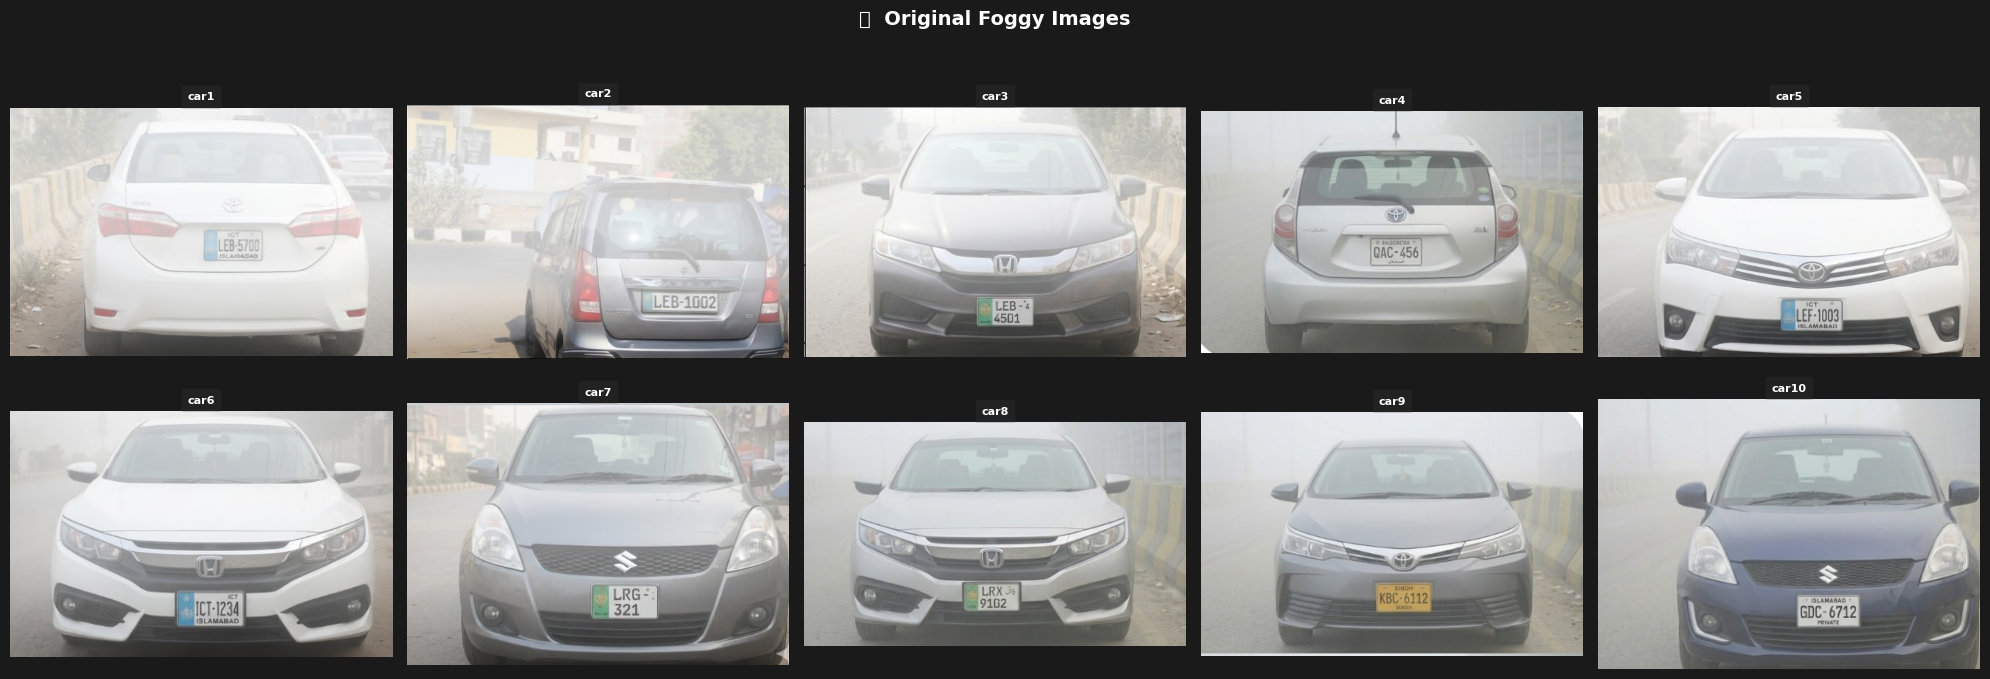

📊 Foggy grid saved  (10 images)


In [10]:
# ============================================================
# Grid 1: Show original foggy images
# ============================================================
n    = len(image_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(image_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('📷  Original Foggy Images', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_foggy.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Foggy grid saved  ({n} images)")

🔄 Removing fog from images...

  ✅ car1.png
  ✅ car2.png
  ✅ car3.png
  ✅ car4.png
  ✅ car5.png
  ✅ car6.png
  ✅ car7.png
  ✅ car8.png
  ✅ car9.png
  ✅ car10.png

✅ 10 images defogged.



/tmp/ipykernel_2096/631919750.py:43: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2096/631919750.py:44: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_preprocessed.png', dpi=150,
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


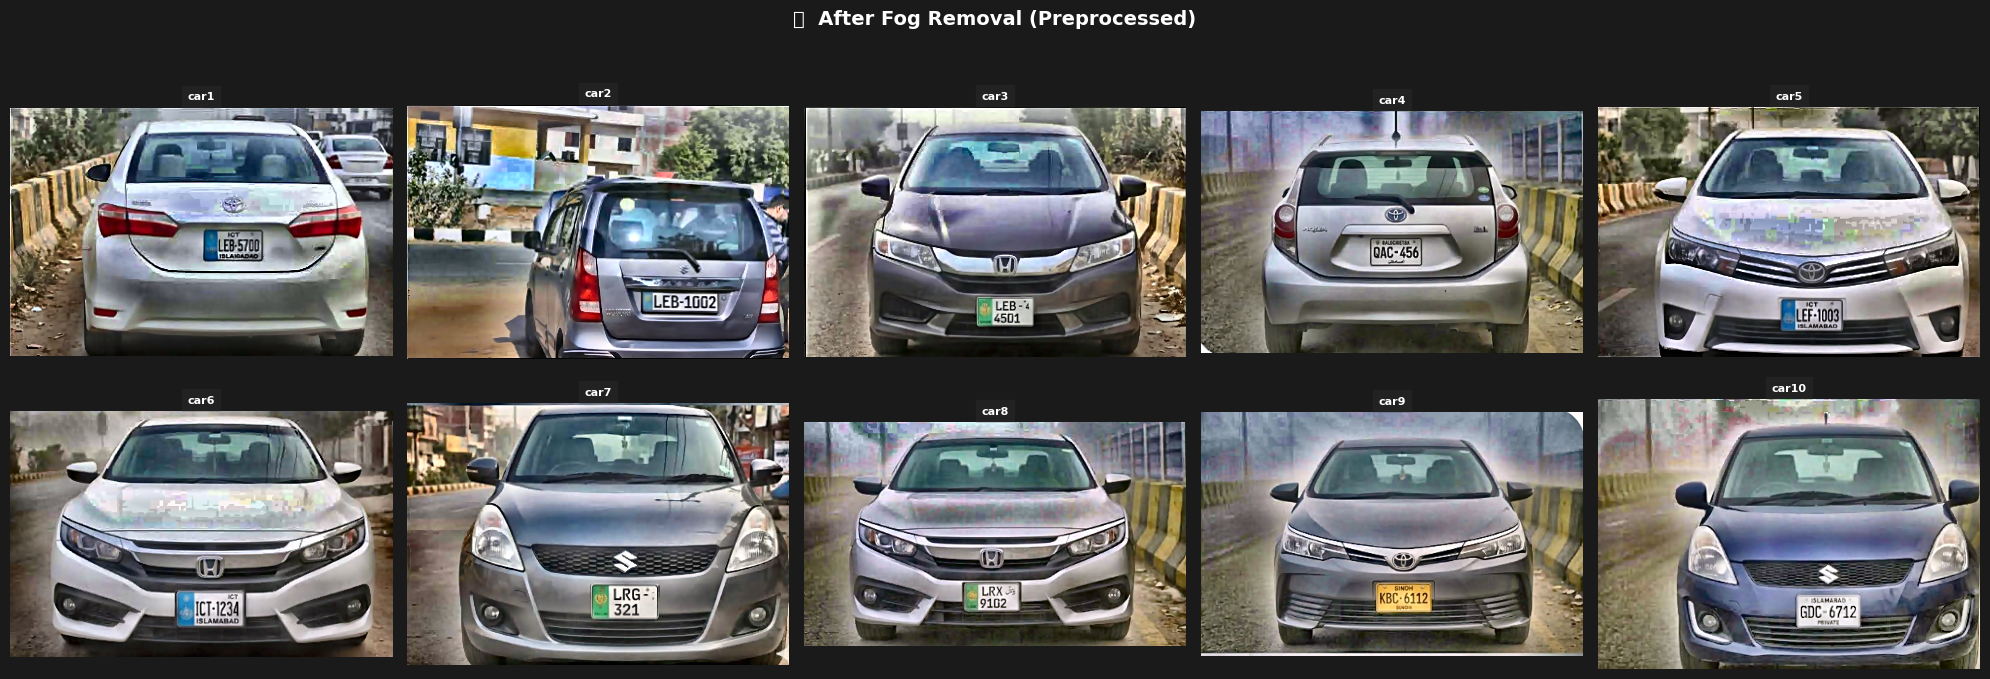

📊 Preprocessed grid saved  (10 images)


In [11]:
# ============================================================
# Apply fog removal and save preprocessed images
# ============================================================
PREPROCESSED_DIR = Path('/content/preprocessed_images')
PREPROCESSED_DIR.mkdir(exist_ok=True)

preprocessed_paths = []
print("🔄 Removing fog from images...\n")

for p in image_paths:
    foggy = Image.open(p).convert('RGB')
    clear = defog_image(foggy)
    out_path = PREPROCESSED_DIR / p.name
    clear.save(str(out_path))
    preprocessed_paths.append(out_path)
    print(f"  ✅ {p.name}")

print(f"\n✅ {len(preprocessed_paths)} images defogged.\n")

# ============================================================
# Grid 2: Show preprocessed (clear) images
# ============================================================
n    = len(preprocessed_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(preprocessed_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('✨  After Fog Removal (Preprocessed)', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_preprocessed.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Preprocessed grid saved  ({n} images)")

In [12]:
# ============================================================
# Run plate detection + OCR + vehicle classification on PREPROCESSED images
# ============================================================
PLATE_CONF = 0.25
CHAR_CONF  = 0.25

results_summary = []

print("🔄 Detecting plates & classifying vehicles on preprocessed images...\n")
for img_path in preprocessed_paths:
    annotated_img, plates, vehicle = process_single_image(
        img_path, plate_model, char_model,
        plate_conf=PLATE_CONF,
        char_conf=CHAR_CONF
    )
    results_summary.append((img_path.name, annotated_img, plates, vehicle))
    print(f"  ✅  {img_path.name:<30}  →  Plate: {', '.join(plates):<20}  Vehicle: {vehicle}")

print(f"\n🏁 Done. Processed {len(results_summary)} preprocessed image(s).")

🔄 Detecting plates & classifying vehicles on preprocessed images...

  ✅  car1.png                        →  Plate: LEB-5700              Vehicle: Toyota_corolla_gen 2014 2016
  ✅  car2.png                        →  Plate: LEB-1002              Vehicle: Suzuki_Wagon R 1st Generation
  ✅  car3.png                        →  Plate: LEB-4501              Vehicle: Honda_Grace
  ✅  car4.png                        →  Plate: QAC-456               Vehicle: Toyota_Aqua 1st Generation
  ✅  car5.png                        →  Plate: LEF-1003              Vehicle: Toyota_corolla_gen 2014 2016
  ✅  car6.png                        →  Plate: CT-1234               Vehicle: Honda_civic_2016
  ✅  car7.png                        →  Plate: LRG-321               Vehicle: Suzuki_Swift 1st Generation
  ✅  car8.png                        →  Plate: LRX-9102              Vehicle: Honda_civic_2016
  ✅  car9.png                        →  Plate: KBC-6112              Vehicle: Toyota_corolla_gen 2014 2016
  ✅  car10.

In [13]:
# ============================================================
# Grid 3: Plate detection + OCR + Vehicle Make/Model results
# ============================================================
n    = len(results_summary)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
axes = np.array(axes).flatten()

for i, (fname, ann_img, plates, vehicle) in enumerate(results_summary):
    axes[i].imshow(ann_img)
    short_name = Path(fname).stem

    axes[i].set_title(
        vehicle.replace('_', ' '), fontsize=8, color='yellow',
        fontweight='bold', pad=4
    )
    axes[i].set_xlabel(
        f"Plate: {', '.join(plates)}", fontsize=10, color='lime',
        fontweight='bold', labelpad=6
    )
    axes[i].tick_params(left=False, bottom=False,
                        labelleft=False, labelbottom=False)
    axes[i].title.set_backgroundcolor('#222222')

    for spine in axes[i].spines.values():
        spine.set_edgecolor('lime')
        spine.set_linewidth(2)

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('🚗 Plate Detection, OCR & Vehicle Classification (After Fog Removal)',
             fontsize=13, color='white', fontweight='bold',
             y=1.01, backgroundcolor='#1a1a1a')

plt.tight_layout()
plt.savefig('/content/batch_results.png', dpi=180,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print("📊 Detection results grid saved to /content/batch_results.png")

Output hidden; open in https://colab.research.google.com to view.

In [14]:
# ============================================================
# Rain Removal Preprocessing (Vertical Median Filter + Inpaint)
# ============================================================

def _vertical_median_filter(image, ksize):
    """Median filter in VERTICAL direction only — removes vertical rain streaks."""
    h, w = image.shape[:2]
    pad = ksize // 2
    if image.ndim == 3:
        padded = np.pad(image, ((pad, pad), (0, 0), (0, 0)), mode="reflect")
        stack = np.stack([padded[i:i+h] for i in range(ksize)], axis=0)
        return np.median(stack, axis=0).astype(np.uint8)
    else:
        padded = np.pad(image, ((pad, pad), (0, 0)), mode="reflect")
        stack = np.stack([padded[i:i+h] for i in range(ksize)], axis=0)
        return np.median(stack, axis=0).astype(np.uint8)

def _build_rain_protection(image):
    """Find text/plate regions from pre-smoothed image (rain edges ignored)."""
    smoothed = cv2.bilateralFilter(image, 9, 75, 75)
    gray = cv2.cvtColor(smoothed, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    density = cv2.blur(edges.astype(np.float32), (25, 25))
    _, mask = cv2.threshold(density, 15.0, 255, cv2.THRESH_BINARY)
    mask = mask.astype(np.uint8)
    mask = cv2.dilate(mask, np.ones((11, 11), np.uint8), iterations=1)
    return mask

def _blend_rain(original, filtered, protect_f):
    """Blend filtered result in, protecting text and rejecting brightening."""
    use = (1.0 - protect_f).copy()
    bright = np.mean(filtered.astype(np.float64) - original.astype(np.float64), axis=2)
    use[bright > 2.0] = 0.0
    result = original.astype(np.float64) * (1.0 - use[:, :, None]) + \
             filtered.astype(np.float64) * use[:, :, None]
    return np.clip(result, 0, 255).astype(np.uint8)

def derain_image(pil_img):
    """Full rain-removal pipeline: vertical median (3 passes) + spot inpaint."""
    bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    protect = _build_rain_protection(bgr)
    protect_f = cv2.GaussianBlur(protect.astype(np.float64), (11, 11), 3.0) / 255.0

    for ksize in (15, 11, 7):
        vmed = _vertical_median_filter(bgr, ksize=ksize)
        bgr = _blend_rain(bgr, vmed, protect_f)

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)
    local_mean = cv2.blur(gray, (15, 15))
    diff = gray - local_mean
    _, spots = cv2.threshold(np.clip(diff, 0, 255).astype(np.uint8), 12, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(spots, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    spot_mask = np.zeros_like(spots)
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if 2 < area < 250:
            cv2.drawContours(spot_mask, [cnt], -1, 255, -1)
    spot_mask[protect > 0] = 0
    spot_mask = cv2.dilate(spot_mask, np.ones((3, 3), np.uint8), iterations=1)
    if np.any(spot_mask > 0):
        bgr = cv2.inpaint(bgr, spot_mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)

    return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))

print("✅ derain_image() preprocessing function defined.")

✅ derain_image() preprocessing function defined.


In [25]:
# ============================================================
# Upload Rainy Images
# ============================================================
from google.colab import files

MAX_RAIN_IMAGES = 10
print(f"📂 Upload up to {MAX_RAIN_IMAGES} rainy images (JPG / PNG / BMP / WEBP)...")
uploaded_rain = files.upload()

RAIN_UPLOAD_DIR = Path('/content/uploaded_rainy_images')
RAIN_UPLOAD_DIR.mkdir(exist_ok=True)
rain_image_paths = []

if not uploaded_rain:
    print("❌ No files uploaded.")
else:
    supported = {'jpg', 'jpeg', 'png', 'bmp', 'webp', 'tif', 'tiff'}
    for fname, data in list(uploaded_rain.items())[:MAX_RAIN_IMAGES]:
        dest = RAIN_UPLOAD_DIR / fname
        dest.write_bytes(data)
        if dest.suffix.lower().lstrip('.') not in supported:
            new_dest = dest.with_suffix('.jpg')
            Image.open(dest).convert('RGB').save(new_dest, 'JPEG')
            dest = new_dest
        rain_image_paths.append(dest)

    if len(uploaded_rain) > MAX_RAIN_IMAGES:
        print(f"⚠️  Only first {MAX_RAIN_IMAGES} of {len(uploaded_rain)} uploads accepted.")
    print(f"\n✅ {len(rain_image_paths)} rainy image(s) ready for processing.")

📂 Upload up to 10 rainy images (JPG / PNG / BMP / WEBP)...


Saving rain_1.png to rain_1 (1).png
Saving rain_2.png to rain_2 (1).png
Saving rain_3.png to rain_3 (1).png
Saving rain5.png to rain5 (2).png
Saving rain7.png to rain7 (2).png
Saving rain10.png to rain10 (2).png
Saving rain12.jpeg to rain12 (2).jpeg
Saving rain13.jpeg to rain13 (2).jpeg

✅ 8 rainy image(s) ready for processing.


/tmp/ipykernel_2096/149169408.py:24: UserWarning: Glyph 127783 (\N{CLOUD WITH RAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2096/149169408.py:25: UserWarning: Glyph 127783 (\N{CLOUD WITH RAIN}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_rainy.png', dpi=150,


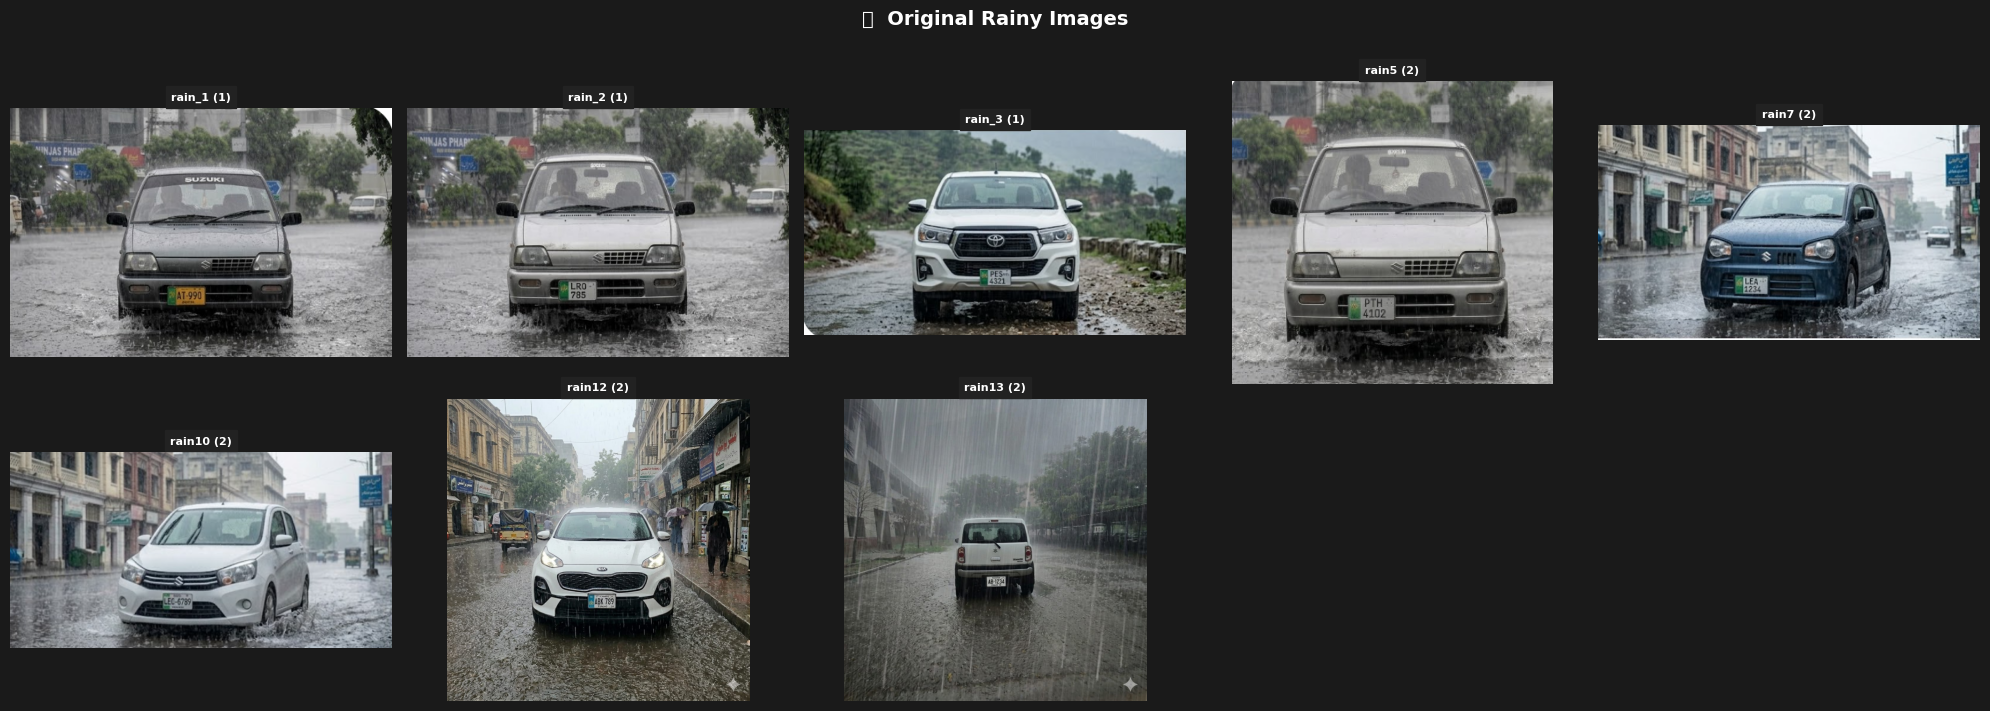

📊 Rainy grid saved  (8 images)


In [26]:
# ============================================================
# Grid 4: Show original rainy images
# ============================================================
n    = len(rain_image_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(rain_image_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('🌧️  Original Rainy Images', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_rainy.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Rainy grid saved  ({n} images)")

🔄 Removing rain from images...

  ✅ rain_1 (1).png
  ✅ rain_2 (1).png
  ✅ rain_3 (1).png
  ✅ rain5 (2).png
  ✅ rain7 (2).png
  ✅ rain10 (2).png
  ✅ rain12 (2).jpeg
  ✅ rain13 (2).jpeg

✅ 8 images derained.



/tmp/ipykernel_2096/380673791.py:43: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2096/380673791.py:44: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_derained.png', dpi=150,


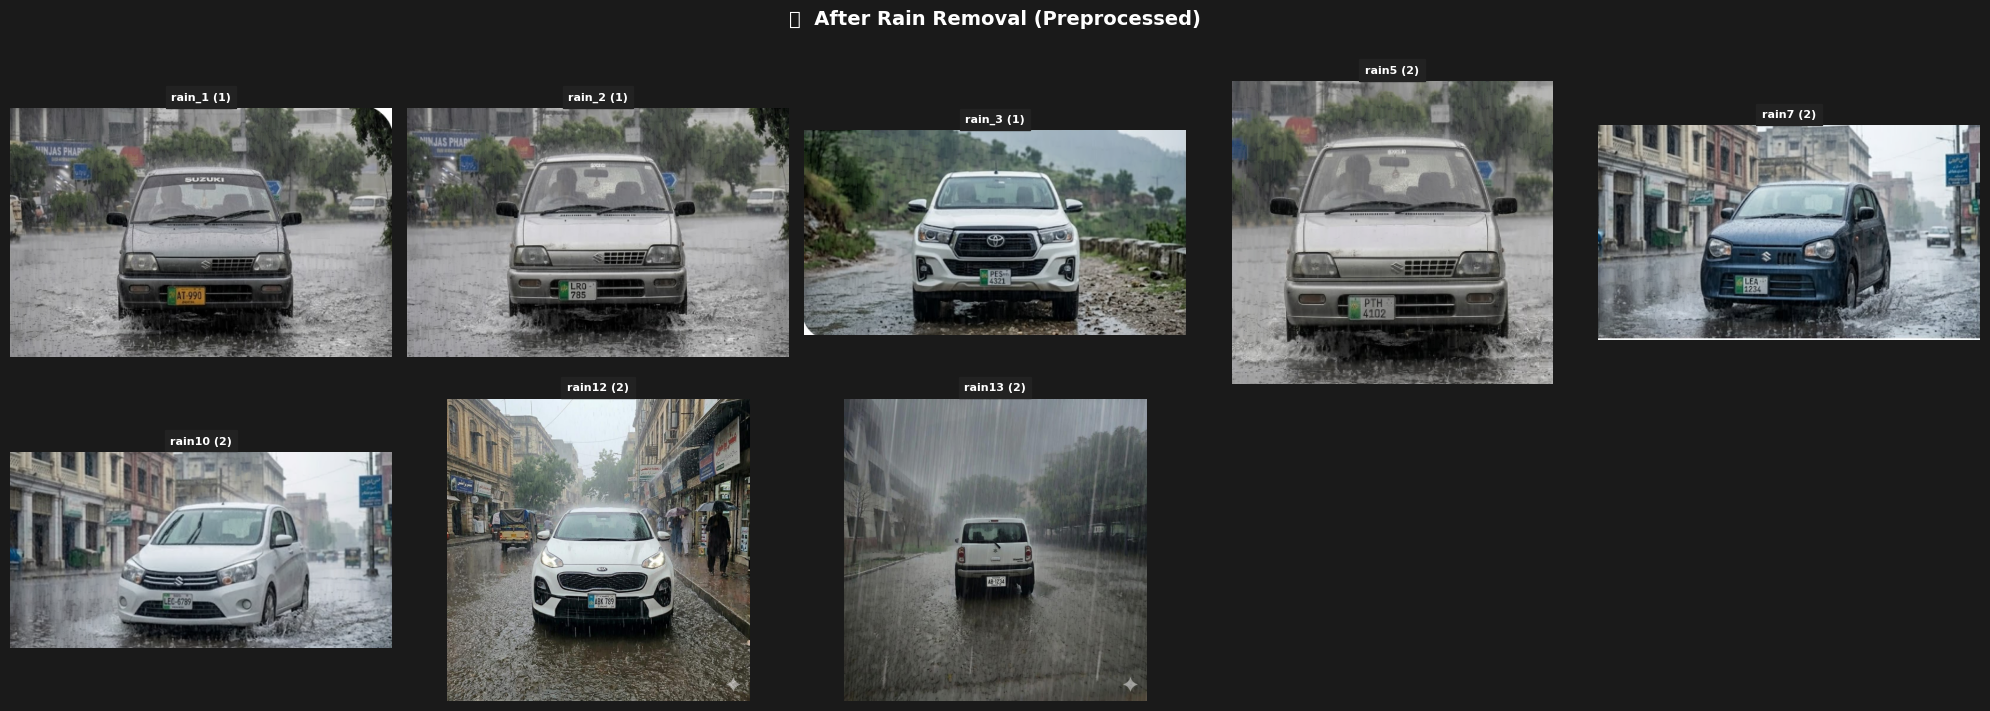

📊 Derained grid saved  (8 images)


In [27]:
# ============================================================
# Apply rain removal and save preprocessed images
# ============================================================
RAIN_PREPROCESSED_DIR = Path('/content/derained_images')
RAIN_PREPROCESSED_DIR.mkdir(exist_ok=True)

derained_paths = []
print("🔄 Removing rain from images...\n")

for p in rain_image_paths:
    rainy = Image.open(p).convert('RGB')
    clear = derain_image(rainy)
    out_path = RAIN_PREPROCESSED_DIR / p.name
    clear.save(str(out_path))
    derained_paths.append(out_path)
    print(f"  ✅ {p.name}")

print(f"\n✅ {len(derained_paths)} images derained.\n")

# ============================================================
# Grid 5: Show derained (clear) images
# ============================================================
n    = len(derained_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(derained_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('✨  After Rain Removal (Preprocessed)', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_derained.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Derained grid saved  ({n} images)")

In [28]:
# ============================================================
# Run plate detection + OCR + vehicle classification on DERAINED images
# ============================================================
rain_results_summary = []

print("🔄 Detecting plates & classifying vehicles on derained images...\n")
for img_path in derained_paths:
    annotated_img, plates, vehicle = process_single_image(
        img_path, plate_model, char_model,
        plate_conf=PLATE_CONF,
        char_conf=CHAR_CONF
    )
    rain_results_summary.append((img_path.name, annotated_img, plates, vehicle))
    print(f"  ✅  {img_path.name:<30}  →  Plate: {', '.join(plates):<20}  Vehicle: {vehicle}")

print(f"\n🏁 Done. Processed {len(rain_results_summary)} derained image(s).")

🔄 Detecting plates & classifying vehicles on derained images...

  ✅  rain_1 (1).png                  →  Plate: AT-990                Vehicle: Suzuki_Mehran
  ✅  rain_2 (1).png                  →  Plate: LRQ-785               Vehicle: Suzuki_Mehran
  ✅  rain_3 (1).png                  →  Plate: PES-4321              Vehicle: Toyota_hilux_8th Generation Facelift
  ✅  rain5 (2).png                   →  Plate: PTH-4102              Vehicle: Suzuki_Mehran
  ✅  rain7 (2).png                   →  Plate: LEA-1234              Vehicle: Suzuki_Alto 8th Generation
  ✅  rain10 (2).png                  →  Plate: LEG-6739              Vehicle: Suzuki_Cultus 3rd Generation
  ✅  rain12 (2).jpeg                 →  Plate: ABK-789               Vehicle: Kia_sportage_generation 2016 2020
  ✅  rain13 (2).jpeg                 →  Plate: AB-1234               Vehicle: Suzuki_Hustler

🏁 Done. Processed 8 derained image(s).


In [29]:
# ============================================================
# Grid 6: Rain — Plate detection + OCR + Vehicle Classification results
# ============================================================
n    = len(rain_results_summary)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
axes = np.array(axes).flatten()

for i, (fname, ann_img, plates, vehicle) in enumerate(rain_results_summary):
    axes[i].imshow(ann_img)
    short_name = Path(fname).stem

    axes[i].set_title(
        vehicle.replace('_', ' '), fontsize=8, color='yellow',
        fontweight='bold', pad=4
    )
    axes[i].set_xlabel(
        f"Plate: {', '.join(plates)}", fontsize=10, color='cyan',
        fontweight='bold', labelpad=6
    )
    axes[i].tick_params(left=False, bottom=False,
                        labelleft=False, labelbottom=False)
    axes[i].title.set_backgroundcolor('#222222')

    for spine in axes[i].spines.values():
        spine.set_edgecolor('cyan')
        spine.set_linewidth(2)

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('🚗 Plate Detection, OCR & Vehicle Classification (After Rain Removal)',
             fontsize=13, color='white', fontweight='bold',
             y=1.01, backgroundcolor='#1a1a1a')

plt.tight_layout()
plt.savefig('/content/rain_batch_results.png', dpi=180,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print("📊 Rain detection results grid saved to /content/rain_batch_results.png")

Output hidden; open in https://colab.research.google.com to view.

In [30]:
from google.colab import files

# Fog grids
files.download('/content/grid_foggy.png')
files.download('/content/grid_preprocessed.png')
files.download('/content/batch_results.png')

# Rain grids
files.download('/content/grid_rainy.png')
files.download('/content/grid_derained.png')
files.download('/content/rain_batch_results.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Done.